# 04 - ELRS detector ROC: CFAR primitive on bench captures

**Question:** At what effective SNR does the ELRS detector reach Pd 0.9 at
a block-level Pfa of 1%, and does the attribution statistic separate ELRS
from the real ambient WiFi in the controls?

Two-level Pfa mapping: the library parameter is a per-BIN pfa (detection
matrix); the question's per-BLOCK Pfa comes from thresholding block
statistics at the (1 - 0.01) quantile of the pooled control-block null
distribution. Measurement basis: docs/p0_signature_report.md (bench
captures, ~1 m, 100 mW). See docs/elrs_detector_report.md.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tacet.dsp import cfar, elrs, features
from tacet.loaders import cs8
from tacet.loaders import manifest as manifest_mod

In [2]:
# --- Configuration ---
PFA_BIN = 0.01          # per-bin false-alarm probability (detection matrix)
PFA_BIN_ATTR = 1e-4     # stricter matrix for attribution statistics
BLOCK_S = 0.1           # 100 ms analysis blocks
NFFT = 1024
BLOCK_PFA_TARGET = 0.01 # per-BLOCK target; threshold from control null
SNR_EFF_LADDER_DB = (-3, -6, -9, -12, -15)  # measured effective SNR targets
SEED = 20260923
SATURATED_CONTROL_ID = "20260919T003427Z_control_000"  # 3.9% rails: excluded
MIX_PAIRS = [
    ("20260919T004638Z_elrs-bench_000", "20260919T003513Z_control_000"),  # 16/16, 3s vs 1s
    ("20260919T004805Z_elrs-bench_000", "20260919T005401Z_control_000"),  # 8/8, 2440
    ("20260919T005239Z_elrs-bench_000", "20260919T005404Z_control_000"),  # 8/8, 2450
    ("20260919T005242Z_elrs-bench_000", "20260919T005408Z_control_000"),  # 8/8, 2465
]
print("config ok")

config ok


In [3]:
def analyze_path(entry):
    """Stream a capture in BLOCK_S blocks; one stats dict per block."""
    fs = entry["sample_rate_sps"]
    path = Path(entry["channels"][0]["path"])
    n_block = int(BLOCK_S * fs)
    rows = []
    for z in cs8.iter_cs8_blocks(str(path), n_block):
        stats = elrs.analyze_block(z, fs, pfa=PFA_BIN, nfft=NFFT,
                                   pfa_attr=PFA_BIN_ATTR)
        stats["capture_id"] = entry["id"]
        stats["label"] = entry["protocol"]
        stats["duration_s"] = entry["duration_s"]
        rows.append({k: v for k, v in stats.items()
                     if k != "floor_median_per_slice"})
    return rows


def roc_curve(y_true, scores):
    """Binary ROC with ties handled at distinct-score boundaries."""
    order = np.argsort(-np.asarray(scores), kind="stable")
    y_s = np.asarray(y_true)[order]
    s_s = np.asarray(scores)[order]
    n_pos = y_s.sum()
    n_neg = len(y_s) - n_pos
    tp = np.cumsum(y_s)
    fp = np.cumsum(1 - y_s)
    distinct = np.r_[s_s[1:] != s_s[:-1], True]
    tpr = np.r_[0.0, tp[distinct] / n_pos]
    fpr = np.r_[0.0, fp[distinct] / n_neg]
    return fpr, tpr


def auc_from_roc(fpr, tpr):
    return float(np.trapezoid(tpr, fpr))


print("helpers ok")

helpers ok


In [4]:
# CFAR sanity 1: nominal vs empirical per-bin Pfa on synthetic noise
# (known noise; mirrors tests/test_cfar.py with an independent seed).
rng = np.random.default_rng(SEED + 1)
n = NFFT * 512
z_syn = (rng.standard_normal(n) + 1j * rng.standard_normal(n)).astype(np.complex64)
_, _, S_syn = features.spectrogram(z_syn, 20e6, nfft=NFFT)
D_syn = cfar.detect_bins(S_syn, PFA_BIN)
center = D_syn.shape[0] // 2
rows = [i for i in range(0, D_syn.shape[0], 3) if abs(i - center) > 4]
emp_syn = float(D_syn[rows, :].mean())
n_eval = len(rows) * D_syn.shape[1]
band_syn = 4.0 * np.sqrt(PFA_BIN * (1 - PFA_BIN) / n_eval)
print(f"synthetic: empirical {emp_syn:.5f} vs nominal {PFA_BIN} "
      f"(4-sigma band {band_syn:.5f})")
assert abs(emp_syn - PFA_BIN) < band_syn, "CFAR model broken on known noise"

synthetic: empirical 0.01025 vs nominal 0.01 (4-sigma band 0.00096)


In [5]:
# Load captures from the manifest (saturated control excluded).
entries = manifest_mod.query()
signals = [e for e in entries if e["protocol"] == "elrs"]
controls_all = [e for e in entries if e["protocol"] == "noise"]
controls = [e for e in controls_all if e["id"] != SATURATED_CONTROL_ID]
print(f"{len(signals)} ELRS captures, {len(controls)} usable controls "
      f"({len(controls_all) - len(controls)} excluded: saturated)")

import time

t0 = time.time()
sig_rows, ctl_rows = [], []
for i, e in enumerate(signals + controls, 1):
    rows = analyze_path(e)
    (sig_rows if e["protocol"] == "elrs" else ctl_rows).extend(rows)
    print(f"[{i:2d}/{len(signals) + len(controls)}] {e['id']} "
          f"({len(rows)} blocks, {time.time() - t0:.0f} s)", flush=True)
sig_df = pd.DataFrame(sig_rows)
ctl_df = pd.DataFrame(ctl_rows)
print(f"signal blocks {len(sig_df)}, control blocks {len(ctl_df)}")

8 ELRS captures, 5 usable controls (1 excluded: saturated)
[ 1/13] 20260919T004638Z_elrs-bench_000 (30 blocks, 5 s)
[ 2/13] 20260919T004805Z_elrs-bench_000 (30 blocks, 10 s)
[ 3/13] 20260919T005239Z_elrs-bench_000 (30 blocks, 15 s)
[ 4/13] 20260919T005242Z_elrs-bench_000 (30 blocks, 19 s)
[ 5/13] 20260919T005913Z_elrs-bench_000 (30 blocks, 24 s)
[ 6/13] 20260921T185929Z_elrs-bench_000 (600 blocks, 121 s)
[ 7/13] 20260921T190035Z_elrs-bench_000 (600 blocks, 217 s)
[ 8/13] 20260921T190155Z_elrs-bench_000 (600 blocks, 313 s)
[ 9/13] 20260919T003513Z_control_000 (10 blocks, 315 s)
[10/13] 20260919T005401Z_control_000 (30 blocks, 320 s)
[11/13] 20260919T005404Z_control_000 (30 blocks, 324 s)
[12/13] 20260919T005408Z_control_000 (30 blocks, 329 s)
[13/13] 20260921T190315Z_control_000 (600 blocks, 426 s)
signal blocks 1950, control blocks 700


In [6]:
# CFAR sanity 2: per-control BIN-LEVEL exceedance rate — the fraction of
# eligible bins above threshold, an upper bound on the field bin-Pfa
# (ambient WiFi genuinely occupies bins, so exceedance >= true Pfa).
def control_exceedance(entry):
    fs = entry["sample_rate_sps"]
    n_block = int(BLOCK_S * fs)
    above = 0
    total = 0
    for z in cs8.iter_cs8_blocks(str(Path(entry["channels"][0]["path"])),
                                 n_block):
        _, _, S = features.spectrogram(features.remove_dc(z), fs, nfft=NFFT)
        D = cfar.detect_bins(S, PFA_BIN)
        above += int(D.sum())
        total += D.size
    return above / total


exc_rows = []
for e in controls:
    rate = control_exceedance(e)
    grp = ctl_df[ctl_df["capture_id"] == e["id"]]
    exc_rows.append({
        "control": e["id"],
        "blocks": len(grp),
        "bin_exceedance": rate,
        "median_max_occ": float(grp["max_occupied_fraction"].median()),
        "p99_max_occ": float(grp["max_occupied_fraction"].quantile(0.99)),
        "median_excess_db": float(grp["excess_db"].median()),
    })
exc_df = pd.DataFrame(exc_rows)
print(exc_df.to_string(index=False))
exc_df

                        control  blocks  ...  p99_max_occ  median_excess_db
0  20260919T003513Z_control_000      10  ...     0.245232         62.118502
1  20260919T005401Z_control_000      30  ...     0.166798         47.818480
2  20260919T005404Z_control_000      30  ...     0.192532         21.621102
3  20260919T005408Z_control_000      30  ...     0.226128         22.207478
4  20260921T190315Z_control_000     600  ...     0.255172         59.612362

[5 rows x 6 columns]

                     control  blocks  bin_exceedance  median_max_occ  p99_max_occ  median_excess_db
20260919T003513Z_control_000      10        0.031508        0.219212     0.245232         62.118502
20260919T005401Z_control_000      30        0.010334        0.077833     0.166798         47.818480
20260919T005404Z_control_000      30        0.016286        0.181281     0.192532         21.621102
20260919T005408Z_control_000      30        0.019454        0.204433     0.226128         22.207478
20260921T190315Z_control_000     600        0.033808        0.213300     0.255172         59.612362


bench ROC AUC (max_occupied_fraction): 0.6686
bench ROC AUC (excess_db): 0.4557
block threshold @ Pfa 0.01: max_occupied_fraction > 0.2542 (from 700 control blocks)
Pd at that threshold: 0.0636


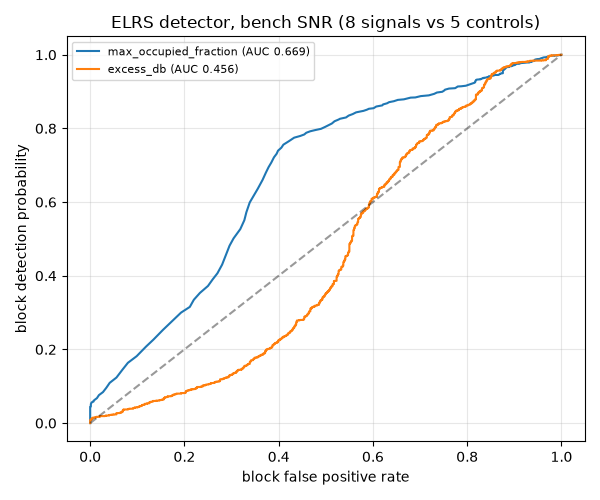

In [7]:
# Detection ROC at bench SNR: block statistic = max_occupied_fraction.
y_bench = np.r_[np.ones(len(sig_df), dtype=bool),
                np.zeros(len(ctl_df), dtype=bool)]
score_occ = np.r_[sig_df["max_occupied_fraction"].to_numpy(),
                  ctl_df["max_occupied_fraction"].to_numpy()]
score_exc = np.r_[sig_df["excess_db"].to_numpy(),
                  ctl_df["excess_db"].to_numpy()]
SCORES_NULL = ctl_df["max_occupied_fraction"].to_numpy()

fpr_occ, tpr_occ = roc_curve(y_bench, score_occ)
fpr_exc, tpr_exc = roc_curve(y_bench, score_exc)
thr_bench = np.quantile(SCORES_NULL, 1.0 - BLOCK_PFA_TARGET)
pd_occ = float((sig_df["max_occupied_fraction"] > thr_bench).mean())
n_ctl_blocks = len(ctl_df)
print(f"bench ROC AUC (max_occupied_fraction): {auc_from_roc(fpr_occ, tpr_occ):.4f}")
print(f"bench ROC AUC (excess_db): {auc_from_roc(fpr_exc, tpr_exc):.4f}")
print(f"block threshold @ Pfa {BLOCK_PFA_TARGET}: max_occupied_fraction > "
      f"{thr_bench:.4f} (from {n_ctl_blocks} control blocks)")
print(f"Pd at that threshold: {pd_occ:.4f}")

plt.figure(figsize=(6, 5))
plt.plot(fpr_occ, tpr_occ, label=f"max_occupied_fraction (AUC {auc_from_roc(fpr_occ, tpr_occ):.3f})")
plt.plot(fpr_exc, tpr_exc, label=f"excess_db (AUC {auc_from_roc(fpr_exc, tpr_exc):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("block false positive rate")
plt.ylabel("block detection probability")
plt.title("ELRS detector, bench SNR (8 signals vs 5 controls)")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# SNR ladder by mixing: alpha solved per pair to hit measured SNR_eff
# targets. SNR_eff = 10 log10(a^2 P / (sigma^2 (a^2 + 1))) with P the
# per-bin signal power (signal PSD minus control PSD, eligible bins) and
# sigma^2 the control PSD. Adding two recorded noise realizations raises
# the floor ~3 dB at alpha = 1, so the ladder starts below bench.
def pair_powers(sig_entry, ctl_entry):
    fs = sig_entry["sample_rate_sps"]
    n_sig = int(min(sig_entry["duration_s"], ctl_entry["duration_s"]) * fs)
    z_s = cs8.load_cs8(Path(sig_entry["channels"][0]["path"]), n_samples=n_sig)
    z_c = cs8.load_cs8(Path(ctl_entry["channels"][0]["path"]), n_samples=n_sig)
    _, psd_s = features.welch_psd(features.remove_dc(z_s), fs, nfft=NFFT)
    _, psd_c = features.welch_psd(features.remove_dc(z_c), fs, nfft=NFFT)
    center_bin = psd_s.size // 2
    elig = np.ones(psd_s.size, dtype=bool)
    elig[center_bin - 4 : center_bin + 5] = False
    p_sig = float(np.clip(psd_s[elig] - psd_c[elig], 0.0, None).mean())
    noise = float(psd_c[elig].mean())
    return z_s, z_c, p_sig, noise, fs


def ladder_rows():
    rows = []
    for sig_id, ctl_id in MIX_PAIRS:
        sig_entry = next(e for e in signals if e["id"] == sig_id)
        ctl_entry = next(e for e in controls_all if e["id"] == ctl_id)
        z_s, z_c, p_sig, noise, fs = pair_powers(sig_entry, ctl_entry)
        bench_snr_db = 10 * np.log10(p_sig / noise)
        for target_db in SNR_EFF_LADDER_DB:
            t_lin = 10 ** (target_db / 10.0)
            if t_lin * noise >= p_sig:
                print(f"skip {sig_id} @ {target_db} dB: beyond bench SNR")
                continue
            a2 = t_lin * noise / (p_sig - t_lin * noise)
            alpha = np.sqrt(a2)
            z_mix = (alpha * z_s.astype(np.complex128)
                     + z_c.astype(np.complex128)).astype(np.complex64)
            n_block = int(BLOCK_S * fs)
            n_blocks = len(z_mix) // n_block
            for b in range(n_blocks):
                stats = elrs.analyze_block(
                    z_mix[b * n_block : (b + 1) * n_block], fs,
                    pfa=PFA_BIN, nfft=NFFT, pfa_attr=PFA_BIN_ATTR)
                stats["capture_id"] = sig_id
                stats["snr_eff_db"] = target_db
                stats["alpha"] = alpha
                rows.append({k: v for k, v in stats.items()
                             if k != "floor_median_per_slice"})
        print(f"pair {sig_id}: bench per-bin SNR {bench_snr_db:+.1f} dB, "
              f"{sum(1 for r in rows if r['capture_id'] == sig_id)} mixed blocks",
              flush=True)
    return rows


ladder_df = pd.DataFrame(ladder_rows())
print(f"ladder blocks: {len(ladder_df)}")
ladder_df.groupby("snr_eff_db")["max_occupied_fraction"].describe()

            count      mean       std  ...       50%       75%       max
snr_eff_db                             ...                              
-15         100.0  0.162286  0.057298  ...  0.184236  0.201232  0.247291
-12         100.0  0.163419  0.056124  ...  0.184236  0.202463  0.248276
-9          100.0  0.164433  0.054942  ...  0.183251  0.201478  0.250246
-6          100.0  0.165133  0.053530  ...  0.182266  0.203202  0.253202
-3          100.0  0.165695  0.052264  ...  0.181281  0.202956  0.263054

[5 rows x 8 columns]

pair 20260919T004638Z_elrs-bench_000: bench per-bin SNR +21.0 dB, 50 mixed blocks
pair 20260919T004805Z_elrs-bench_000: bench per-bin SNR +11.3 dB, 150 mixed blocks
pair 20260919T005239Z_elrs-bench_000: bench per-bin SNR +10.1 dB, 150 mixed blocks
pair 20260919T005242Z_elrs-bench_000: bench per-bin SNR +14.8 dB, 150 mixed blocks
ladder blocks: 500


In [9]:
# Deliverable: Pd at block-Pfa 1% vs measured SNR_eff (pooled control
# blocks as the null; mixed blocks as positives per rung).
ctl_null = ctl_df["max_occupied_fraction"].to_numpy()
thr = np.quantile(ctl_null, 1.0 - BLOCK_PFA_TARGET)
curve = []
for target_db, grp in ladder_df.groupby("snr_eff_db"):
    mixed = grp["max_occupied_fraction"].to_numpy()
    pd_val = float((mixed > thr).mean())
    # One-sided AUC: P(mixed block > control block), ties count 0.5 —
    # same control null the Pfa threshold is derived from. (roc_curve
    # with all-positive labels has no negatives: division by zero.)
    auc_null = float((mixed[:, None] > ctl_null[None, :]).mean()
                     + 0.5 * (mixed[:, None] == ctl_null[None, :]).mean())
    curve.append({"snr_eff_db": target_db, "blocks": len(grp),
                  "pd_at_pfa1pct": pd_val,
                  "auc_vs_control_null": auc_null})
curve_df = pd.DataFrame(curve)
print(f"threshold from {len(ctl_null)} control blocks: "
      f"max_occupied_fraction > {thr:.4f}")
curve_df

   snr_eff_db  blocks  pd_at_pfa1pct  auc_vs_control_null
0         -15     100           0.00             0.310764
1         -12     100           0.00             0.314600
2          -9     100           0.00             0.316671
3          -6     100           0.00             0.316950
4          -3     100           0.01             0.314450

threshold from 700 control blocks: max_occupied_fraction > 0.2542


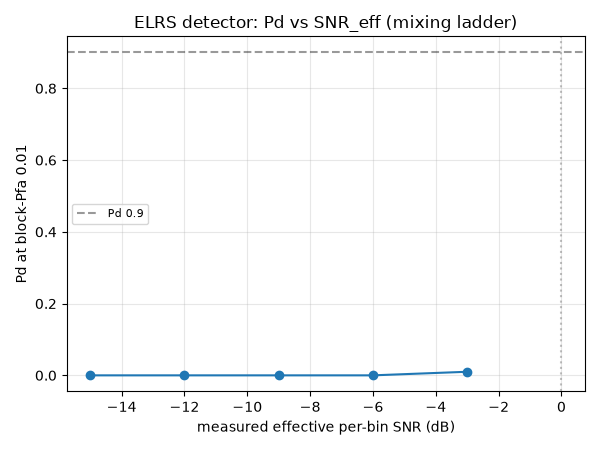

In [10]:
plt.figure(figsize=(6, 4.5))
plt.plot(curve_df["snr_eff_db"], curve_df["pd_at_pfa1pct"], "o-")
plt.axhline(0.9, color="k", ls="--", alpha=0.4, label="Pd 0.9")
plt.axvline(0.0, color="gray", ls=":", alpha=0.5)
plt.xlabel("measured effective per-bin SNR (dB)")
plt.ylabel(f"Pd at block-Pfa {BLOCK_PFA_TARGET}")
plt.title("ELRS detector: Pd vs SNR_eff (mixing ladder)")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

attribution AUC (bin_diversity_attr): 0.7112
attribution AUC (turnover_attr): 0.4376


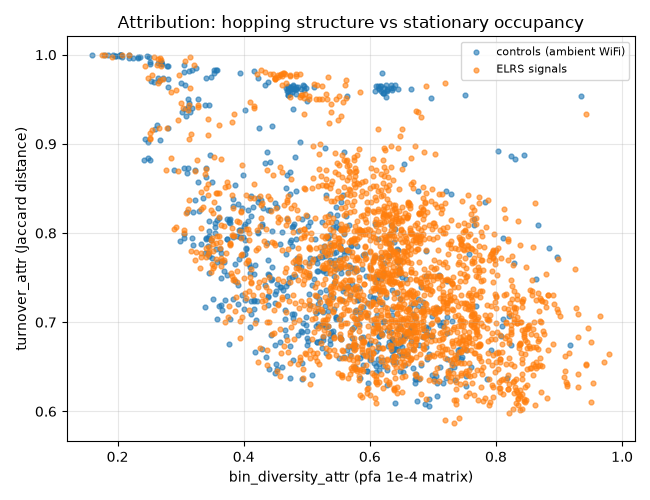

In [11]:
# Attribution: ELRS blocks vs control blocks on the stricter matrix.
x_sig = sig_df["bin_diversity_attr"].to_numpy()
x_ctl = ctl_df["bin_diversity_attr"].to_numpy()
y_attr = np.r_[np.ones(len(x_sig), dtype=bool),
               np.zeros(len(x_ctl), dtype=bool)]

plt.figure(figsize=(6.5, 5))
plt.scatter(x_ctl, ctl_df["turnover_attr"], s=12, alpha=0.6, label="controls (ambient WiFi)")
plt.scatter(x_sig, sig_df["turnover_attr"], s=12, alpha=0.6, label="ELRS signals")
plt.xlabel("bin_diversity_attr (pfa 1e-4 matrix)")
plt.ylabel("turnover_attr (Jaccard distance)")
plt.title("Attribution: hopping structure vs stationary occupancy")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for name, vals in (("bin_diversity_attr", np.r_[x_sig, x_ctl]),
                   ("turnover_attr", np.r_[sig_df["turnover_attr"].to_numpy(),
                                           ctl_df["turnover_attr"].to_numpy()])):
    fpr_a, tpr_a = roc_curve(y_attr, vals)
    print(f"attribution AUC ({name}): {auc_from_roc(fpr_a, tpr_a):.4f}")

## Honest-results note

- Mixing adds two recorded noise realizations and scales the signal
  digitally: it does not reproduce a weaker signal at the antenna (noise
  figure / AGC effects are not modeled; gains were manual and matched).
- SNR_eff is measured per pair from PSD differences, not assumed from the
  scale factor alpha; the floor rise (~3 dB at alpha = 1) is inherent to
  the method and is why the ladder starts below bench SNR.
- Bench-only distances (~1 m): no range claim until the walk-test.
- The block threshold and Pfa rest on the pooled control blocks
  (3 s + 60 s controls; counts printed above) — small-null quantiles are
  coarse at 1%.
- D500 packet timing is unverified (out of scope); ambient WiFi in the
  controls is whatever was in the air that day, not a controlled source.
- Controls table reports EXCEEDANCE rates, not model error: real
  occupancy and model error are indistinguishable without ground truth.

## Measurement basis

Bench characterization: docs/p0_signature_report.md (notebook 01).
Threshold derivation and detector design:
.opencode/superpowers/specs/2026-09-23-elrs-detector-design.md (local).
Receive-only analysis of own captures; no transmission.